# Exercício de Práctica — CRISP-DM: Previsão de Duração de Corridas de Táxi (NYC)

**Curso:** Gestão Ágil de Projetos em Ciência de Dados e Inteligência Artificial II
**Baseado em:** projeto_taxi_crispdm (material de referência do Módulo II)

## 1. Entendimento do Negócio

**Pergunta de negócio:** como estimar, com erro aceitável, a duração de uma corrida
de táxi a partir de informações temporais, geográficas e operacionais disponíveis
*antes* do fim da viagem?

**Por que importa:** a duração estimada afeta a expectativa do passageiro, o
planejamento do motorista, a alocação de frota e a análise de eficiência urbana
(ETA — Estimated Time of Arrival).

**Problema de dados:** regressão supervisionada. O *target* é `duration_min`,
calculado como a diferença entre o horário de desembarque e o horário de embarque.

**Fonte:** dados públicos e reais da NYC Taxi & Limousine Commission (TLC).


## 2. Setup — imports e configuração

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

## 3. Entendimento dos Dados — carregamento

Os dados são publicados mensalmente pela TLC em formato `.parquet`. Para manter
o exercício leve, carregamos apenas 1-2 meses com uma amostra de linhas.


In [2]:
DATA_URLS = {
    '2026-01': 'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-01.parquet',
    '2026-02': 'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-02.parquet',
}

ZONE_URL = 'https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv'

RAW_COLUMNS = [
    'VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
    'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
    'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount',
    'tip_amount', 'total_amount'
]

USE_MONTHS = ['2026-01', '2026-02']
MAX_ROWS_PER_MONTH = 20_000


def load_month(label, url, max_rows=20_000):
    month = pd.read_parquet(url, columns=RAW_COLUMNS)
    month['source_month'] = label
    if len(month) > max_rows:
        month = month.sample(max_rows, random_state=RANDOM_STATE)
    return month


frames = [load_month(m, DATA_URLS[m], MAX_ROWS_PER_MONTH) for m in USE_MONTHS]
df_raw = pd.concat(frames, ignore_index=True)
zones = pd.read_csv(ZONE_URL)

print(df_raw.shape)
df_raw.head()

(40000, 14)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount,source_month
0,1,2026-01-18 12:35:13,2026-01-18 12:46:05,1.0,3.90,1.0,N,68,238,1,17.00,2.50,24.25,2026-01
1,2,2026-01-28 01:01:57,2026-01-28 01:34:45,NaN,13.95,NaN,None,69,61,0,49.13,0.00,58.09,2026-01
2,2,2026-01-09 10:35:27,2026-01-09 11:05:50,1.0,13.79,1.0,N,13,138,1,55.50,19.57,84.82,2026-01
3,2,2026-01-24 22:26:51,2026-01-24 22:37:03,1.0,1.76,1.0,N,164,79,2,11.40,0.00,17.15,2026-01
4,2,2026-01-01 01:59:23,2026-01-01 02:13:41,NaN,7.42,NaN,None,74,232,0,41.06,0.00,45.81,2026-01


In [3]:
print('Linhas:', len(df_raw))
print('Colunas:', df_raw.shape[1])
display(df_raw.dtypes.to_frame('dtype'))
display(df_raw.isna().mean().sort_values(ascending=False).to_frame('proporcao_nulos').head(10))

Linhas: 40000
Colunas: 14


,dtype
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,object
PULocationID,int32
DOLocationID,int32
payment_type,int64


,proporcao_nulos
RatecodeID,0.294325
passenger_count,0.294325
store_and_fwd_flag,0.294325
tpep_pickup_datetime,0.000000
tpep_dropoff_datetime,0.000000
VendorID,0.000000
trip_distance,0.000000
PULocationID,0.000000
DOLocationID,0.000000
payment_type,0.000000


## 4. Preparação dos Dados

Pontos importantes:
- O *target* é derivado dos timestamps — precisamos validar datas impossíveis.
- Algumas variáveis existem apenas *depois* da corrida (ex.: `tip_amount`,
  `total_amount`) e causariam **vazamento de dados** se usadas como feature
  para prever a duração antes da viagem começar — por isso não entram no
  conjunto de features do modelo.
- Filtros de qualidade (duração, distância, tarifa, passageiros) devem ser
  documentados, pois alteram a população analisada.


In [4]:
def prepare_data(df_raw, zones):
    df = df_raw.copy()
    df['pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
    df['dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])
    df['duration_min'] = (df['dropoff_datetime'] - df['pickup_datetime']).dt.total_seconds() / 60

    pu_zones = zones.add_prefix('PU_')
    do_zones = zones.add_prefix('DO_')
    df = df.merge(pu_zones, left_on='PULocationID', right_on='PU_LocationID', how='left')
    df = df.merge(do_zones, left_on='DOLocationID', right_on='DO_LocationID', how='left')

    before = len(df)
    quality_mask = (
        df['duration_min'].between(1, 120)
        & df['trip_distance'].between(0.1, 50)
        & df['fare_amount'].gt(0)
        & df['passenger_count'].between(1, 6)
    )
    df = df.loc[quality_mask].copy()
    after = len(df)

    df['pickup_hour'] = df['pickup_datetime'].dt.hour
    df['pickup_dayofweek'] = df['pickup_datetime'].dt.dayofweek
    df['pickup_month'] = df['pickup_datetime'].dt.month
    df['is_weekend'] = df['pickup_dayofweek'].isin([5, 6]).astype(int)
    df['same_borough'] = (df['PU_Borough'] == df['DO_Borough']).astype(int)
    df['airport_trip'] = (
        df['PU_Zone'].fillna('').str.contains('Airport', case=False)
        | df['DO_Zone'].fillna('').str.contains('Airport', case=False)
    ).astype(int)

    print(f'Registros antes dos filtros: {before:,}')
    print(f'Registros apos filtros: {after:,}')
    print(f'Remocao: {(1 - after / before):.1%}')
    return df


df = prepare_data(df_raw, zones)
df.head()

Registros antes dos filtros: 40,000
Registros apos filtros: 26,771
Remocao: 33.1%


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,DO_LocationID,DO_Borough,DO_Zone,DO_service_zone,pickup_hour,pickup_dayofweek,pickup_month,is_weekend,same_borough,airport_trip
0,1,2026-01-18 12:35:13,2026-01-18 12:46:05,1.0,3.90,1.0,N,68,238,1,...,238,Manhattan,Upper West Side North,Yellow Zone,12,6,1,1,1,0
2,2,2026-01-09 10:35:27,2026-01-09 11:05:50,1.0,13.79,1.0,N,13,138,1,...,138,Queens,LaGuardia Airport,Airports,10,4,1,0,0,1
3,2,2026-01-24 22:26:51,2026-01-24 22:37:03,1.0,1.76,1.0,N,164,79,2,...,79,Manhattan,East Village,Yellow Zone,22,5,1,1,1,0
5,2,2026-01-27 09:30:30,2026-01-27 09:44:06,2.0,1.21,1.0,N,141,262,1,...,262,Manhattan,Yorkville East,Yellow Zone,9,1,1,0,1,0
7,2,2026-01-22 21:18:42,2026-01-22 21:32:22,1.0,2.98,1.0,N,229,238,1,...,238,Manhattan,Upper West Side North,Yellow Zone,21,3,1,0,1,0


## 5. Análise Exploratória (EDA)

Foco: quando as corridas demoram mais, quais segmentos concentram maior
variabilidade e quais variáveis parecem explicar a duração?


,count,mean,std,min,1%,5%,50%,95%,99%,max
duration_min,26771.0,17.138133,14.647386,1.016667,2.266667,3.833333,12.783333,47.025,75.276667,119.75
trip_distance,26771.0,3.359529,4.452405,0.100000,0.300000,0.500000,1.660000,14.505,20.000000,47.26
passenger_count,26771.0,1.244518,0.640536,1.000000,1.000000,1.000000,1.000000,2.000,4.000000,6.00
fare_amount,26771.0,19.326732,17.295854,0.010000,4.400000,5.800000,13.500000,62.500,79.790000,257.80


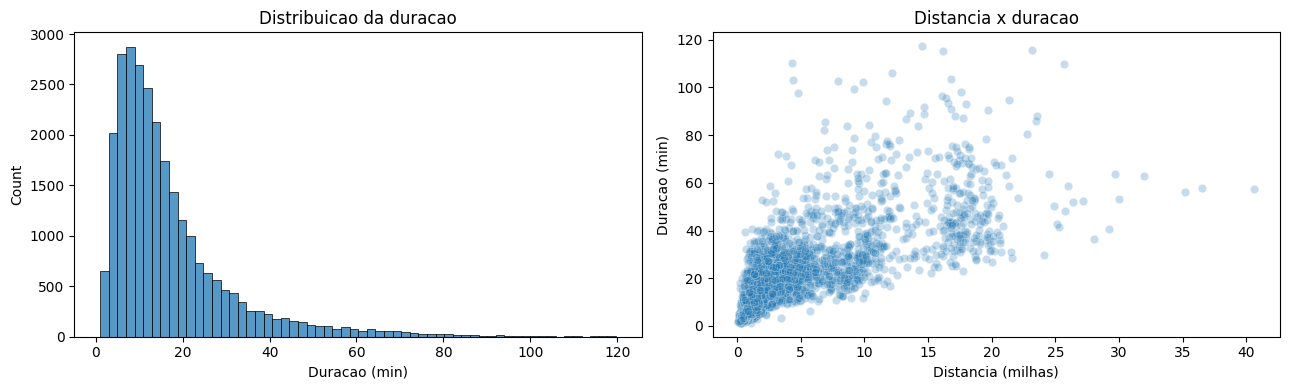

In [5]:
summary = df[['duration_min', 'trip_distance', 'passenger_count', 'fare_amount']].describe(
    percentiles=[.01, .05, .5, .95, .99]
).T
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['duration_min'], bins=60, ax=axes[0])
axes[0].set_title('Distribuicao da duracao')
axes[0].set_xlabel('Duracao (min)')

sample_plot = df.sample(min(5_000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample_plot, x='trip_distance', y='duration_min', alpha=0.25, ax=axes[1])
axes[1].set_title('Distancia x duracao')
axes[1].set_xlabel('Distancia (milhas)')
axes[1].set_ylabel('Duracao (min)')
plt.tight_layout()
plt.savefig('../reports_taxi_exercicio_fig1.png', dpi=100)
plt.show()

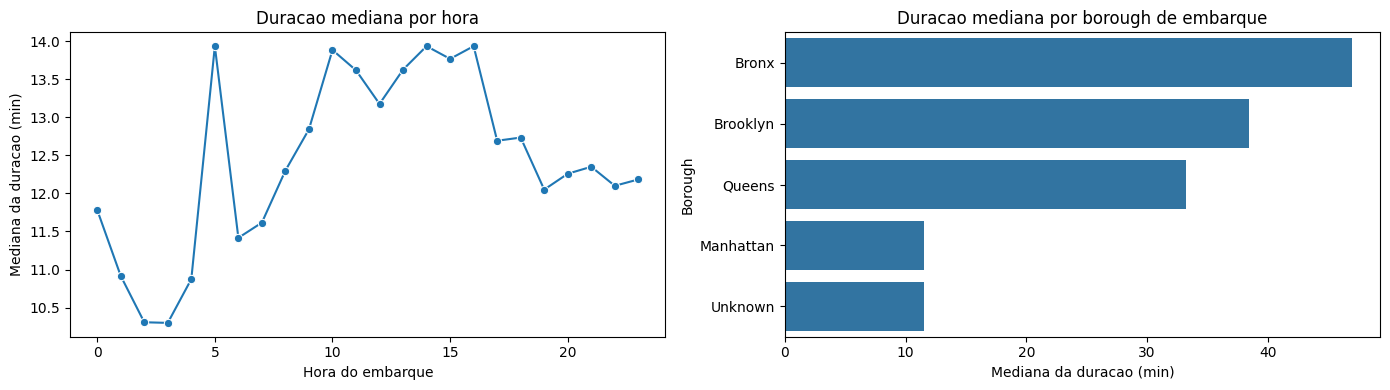

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

hourly = df.groupby('pickup_hour')['duration_min'].agg(['count', 'mean', 'median']).reset_index()
sns.lineplot(data=hourly, x='pickup_hour', y='median', marker='o', ax=axes[0])
axes[0].set_title('Duracao mediana por hora')
axes[0].set_xlabel('Hora do embarque')
axes[0].set_ylabel('Mediana da duracao (min)')

borough = df.groupby('PU_Borough')['duration_min'].median().sort_values(ascending=False).reset_index()
sns.barplot(data=borough, x='duration_min', y='PU_Borough', ax=axes[1])
axes[1].set_title('Duracao mediana por borough de embarque')
axes[1].set_xlabel('Mediana da duracao (min)')
axes[1].set_ylabel('Borough')
plt.tight_layout()
plt.savefig('../reports_taxi_exercicio_fig2.png', dpi=100)
plt.show()

## 6. Preparação para Modelagem

**Validação temporal:** registros mais antigos para treino, mais recentes para
teste. Mais realista do que um split aleatório quando o produto será usado
sobre dados futuros.


In [ ]:
numeric_features = [
    'trip_distance', 'passenger_count', 'pickup_hour', 'pickup_dayofweek',
    'pickup_month', 'is_weekend', 'same_borough', 'airport_trip'
]

categorical_features = [
    'VendorID', 'RatecodeID', 'store_and_fwd_flag',
    'PULocationID', 'DOLocationID', 'PU_Borough', 'DO_Borough'
]

target = 'duration_min'
model_columns = numeric_features + categorical_features

df_model = df.sort_values('pickup_datetime').dropna(subset=[target]).copy()
split_idx = int(len(df_model) * 0.8)

train = df_model.iloc[:split_idx]
test = df_model.iloc[split_idx:]

X_train, y_train = train[model_columns], train[target]
X_test, y_test = test[model_columns], test[target]

print('Treino:', X_train.shape, train['pickup_datetime'].min(), 'a', train['pickup_datetime'].max())
print('Teste:', X_test.shape, test['pickup_datetime'].min(), 'a', test['pickup_datetime'].max())

Treino: (21416, 15) 2026-01-01 00:04:05 a 2026-02-17 10:05:49
Teste: (5355, 15) 2026-02-17 10:12:05 a 2026-02-28 23:58:25


In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

## 7. Modelagem

Comparação entre um baseline ingênuo (mediana) e três modelos, do mais simples
(Ridge, linear) ao mais complexo (HistGradientBoosting). O objetivo não é
apenas ganhar métrica, mas mostrar trade-offs de interpretabilidade, tempo de
treino e risco de overfitting — a mesma lógica do baseline de Cox antes do
DeepSurv no seu TCC.


In [9]:
models = {
    'baseline_mediana': DummyRegressor(strategy='median'),
    'ridge': Ridge(alpha=1.0),
    'random_forest': RandomForestRegressor(
        n_estimators=80, max_depth=18, min_samples_leaf=8,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'hist_gradient_boosting': HistGradientBoostingRegressor(
        max_iter=180, learning_rate=0.07, max_leaf_nodes=31,
        l2_regularization=0.05, random_state=RANDOM_STATE
    )
}


def evaluate_predictions(y_true, y_pred):
    ae = np.abs(y_true - y_pred)
    return {
        'MAPE': mean_absolute_percentage_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
        'Erro_p90': np.percentile(ae, 90)
    }


results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', estimator)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    metrics = evaluate_predictions(y_test, preds)
    metrics['modelo'] = name
    results.append(metrics)
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).set_index('modelo').sort_values('MAPE')
display(results_df)

,MAPE,RMSE,R2,Erro_p90
modelo,,,,
hist_gradient_boosting,0.313485,5.879731,0.822062,8.431715
random_forest,0.325597,6.162985,0.804505,8.755794
ridge,0.500870,7.433879,0.715564,10.054149
baseline_mediana,0.691783,14.461901,-0.076477,19.850000


## 8. Avaliação e Interpretação

A avaliação precisa responder se o modelo ajuda a decisão de negócio — não
apenas olhar a média geral, mas os segmentos onde o erro é maior.


In [10]:
best_name = results_df.index[0]
best_model = fitted_models[best_name]
test_eval = test.copy()
test_eval['pred_duration_min'] = best_model.predict(X_test)
test_eval['abs_error'] = (test_eval['duration_min'] - test_eval['pred_duration_min']).abs()

print('Melhor modelo por MAPE:', best_name)
display(test_eval[['duration_min', 'pred_duration_min', 'abs_error']].describe().T)

segment_error = (
    test_eval.groupby('PU_Borough')
    .agg(corridas=('abs_error', 'size'), MAE=('abs_error', 'mean'))
    .query('corridas >= 20')
    .sort_values('MAE', ascending=False)
)
display(segment_error)

Melhor modelo por MAPE: hist_gradient_boosting


,count,mean,std,min,25%,50%,75%,max
duration_min,5355.0,16.638005,13.940028,1.016667,7.800000,12.750000,20.066667,116.983333
pred_duration_min,5355.0,18.340357,13.652516,0.474502,9.491772,14.433535,22.400540,98.622788
abs_error,5355.0,3.973408,4.334370,0.000883,1.346836,2.796901,5.056229,54.362868


,corridas,MAE
PU_Borough,,
Bronx,41,9.832625
Brooklyn,101,8.823104
Queens,472,7.428931
Manhattan,4732,3.477184


,feature,importance_mae
0,trip_distance,8.620730
2,pickup_hour,1.012660
3,pickup_dayofweek,0.475610
12,DOLocationID,0.242314
9,RatecodeID,0.222510
11,PULocationID,0.125614
13,PU_Borough,0.110230
7,airport_trip,0.012670
1,passenger_count,0.008856
14,DO_Borough,0.008198


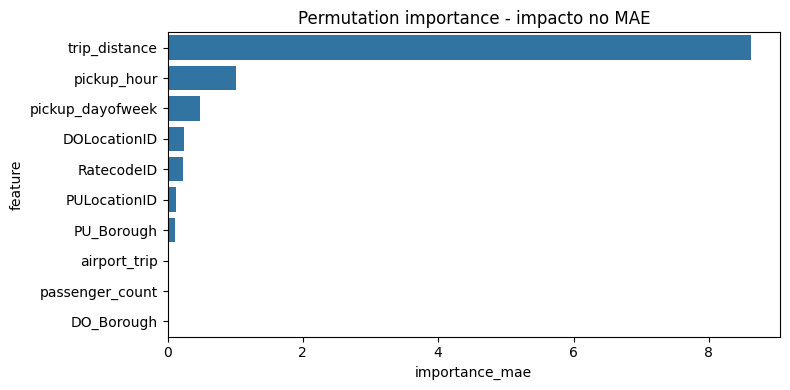

In [11]:
importance_sample = test_eval.sample(min(1_000, len(test_eval)), random_state=RANDOM_STATE)
perm = permutation_importance(
    best_model, importance_sample[model_columns], importance_sample[target],
    n_repeats=5, random_state=RANDOM_STATE, scoring='neg_mean_absolute_error'
)

importance_df = (
    pd.DataFrame({'feature': model_columns, 'importance_mae': perm.importances_mean})
    .sort_values('importance_mae', ascending=False)
)
display(importance_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=importance_df.head(10), x='importance_mae', y='feature')
plt.title('Permutation importance - impacto no MAE')
plt.tight_layout()
plt.savefig('../reports_taxi_exercicio_fig3.png', dpi=100)
plt.show()

## 9. Gestão do Projeto e Riscos

| Risco | Impacto | Mitigação |
|---|---|---|
| Volume de dados alto | Notebook lento ou quebra por memória | Começar com amostra e escalar depois |
| Dados externos indisponíveis | Aula/projeto travado | Baixar amostra local ou ter backup de meses anteriores |
| Vazamento de dados | Resultado artificialmente bom | Separar variáveis disponíveis antes/depois da predição |
| Validação aleatória inadequada | Métrica otimista | Usar split temporal |
| Modelo complexo demais | Difícil explicar no TCC | Comparar com baseline e modelo simples |
| Escopo grande | Atraso no cronograma | Sprint 1 = PoC; Sprint 2 = EDA; Sprint 3 = modelos; Sprint 4 = texto/deployment |

## 10. Conclusão esperada

Ao final da execução, você deve conseguir responder:
- Qual foi o problema de negócio?
- Quais dados foram usados e quais são suas limitações?
- Como o *target* foi construído?
- Quais *features* foram criadas e por quê?
- Qual baseline foi usado?
- Quais modelos foram comparados e qual métrica decidiu o melhor?
- Onde o modelo erra mais?
- Como o modelo seria implantado e monitorado?

**Paralelo com seu TCC:** este mesmo roteiro (Entendimento → Dados → Preparação
→ EDA → Modelagem com baseline → Avaliação por segmento → Deployment) é
exatamente o que você já aplicou com Cox como baseline e DeepSurv como modelo
mais complexo — a diferença é que aqui o alvo é `duration_min` (regressão) e
no seu TCC é tempo até o evento com censura (sobrevivência).
